Enter the number of compartments: 6



Enter 'cat' for catenary models. Enter 'cyc' for cycle models. Enter 'mam1' or 'mam2' for mammillary models (number is central compartment). To enter edges manually, press enter: cyc




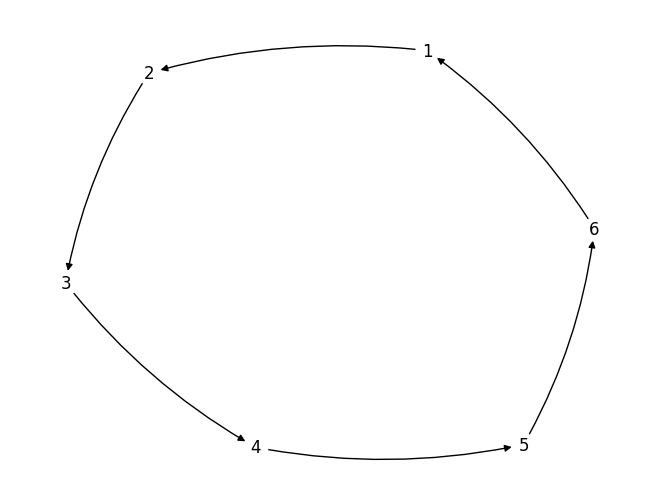




Enter the location of an input, or press enter if done: 1

Enter the location of an input, or press enter if done: 



Enter the location of an output, or press enter if done: 3

Enter the location of an output, or press enter if done: 



Enter the location of a leak, or press enter if done: 6

Enter the location of a leak, or press enter if done: 



A = 

⎡-k₂ ₁    0      0      0      0        k₁ ₆    ⎤
⎢                                               ⎥
⎢k₂ ₁   -k₃ ₂    0      0      0         0      ⎥
⎢                                               ⎥
⎢  0    k₃ ₂   -k₄ ₃    0      0         0      ⎥
⎢                                               ⎥
⎢  0      0    k₄ ₃   -k₅ ₄    0         0      ⎥
⎢                                               ⎥
⎢  0      0      0    k₅ ₄   -k₆ ₅       0      ⎥
⎢                                               ⎥
⎣  0      0      0      0    k₆ ₅   -k₀ ₆ - k₁ ₆⎦






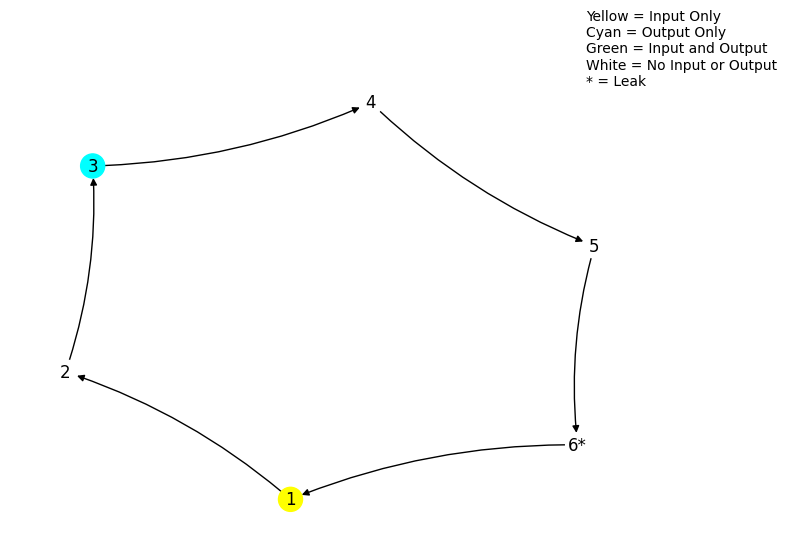





dI - A = 

⎡d + k₂ ₁     0         0         0         0           -k₁ ₆     ⎤
⎢                                                                 ⎥
⎢ -k₂ ₁    d + k₃ ₂     0         0         0             0       ⎥
⎢                                                                 ⎥
⎢   0       -k₃ ₂    d + k₄ ₃     0         0             0       ⎥
⎢                                                                 ⎥
⎢   0         0       -k₄ ₃    d + k₅ ₄     0             0       ⎥
⎢                                                                 ⎥
⎢   0         0         0       -k₅ ₄    d + k₆ ₅         0       ⎥
⎢                                                                 ⎥
⎣   0         0         0         0       -k₆ ₅    d + k₀ ₆ + k₁ ₆⎦



The ODEs for SIAN are: 

dx1/dt = k_1_6*x6 - k_2_1*x1 + u1(t),
dx2/dt = k_2_1*x1 - k_3_2*x2,
dx3/dt = k_3_2*x2 - k_4_3*x3,
y3 = x3,
dx4/dt = k_4_3*x3 - k_5_4*x4,
dx5/dt = k_5_4*x4 - k_6_5*x5,
dx6/dt = k_6_5*x5 + x6*(-k_0_6 - k_1_6),



In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import sympy as sp


G = nx.MultiDiGraph()

#Prompt for number of compartments
compartments = input("Enter the number of compartments: ")
compartments = int(compartments)
print("\n")

model_class = input("\nEnter 'cat' for catenary models. Enter 'cyc' for cycle models. Enter 'mam1' or 'mam2' for mammillary models (number is central compartment). To enter edges manually, press enter: ")


#Mammillary model template
if model_class == "mam1":
  print("\n")
  for i in range(compartments):
    G.add_node(i+1)
  j = 1
  while j < compartments:
    G.add_edge(1,j+1)
    G.add_edge(j+1,1)
    j+= 1

elif model_class == "mam2":
  print("\n")
  for i in range(compartments):
    G.add_node(i+1)
  j = 1
  while j <= compartments:
    if j != 2:
      G.add_edge(2,j)
      G.add_edge(j,2)
    j += 1

#Catenary model template
elif model_class == "cat":
  print("\n")
  for i in range(compartments):
    G.add_node(i+1)
  for i in range(compartments):
    if i == 0:
      G.add_edge(i+1, i+2)
    elif i == compartments - 1:
      G.add_edge(i+1, i)
    else:
      G.add_edge(i+1, i)
      G.add_edge(i+1, i+2)

#Cycle model template
elif model_class == "cyc":
  print("\n")
  for i in range(compartments):
    G.add_node(i+1)
  for i in range(compartments):
    if i == compartments - 1:
      G.add_edge(i+1,1)
    else:
      G.add_edge(i+1, i+2)

#Manually enter edges in other model types
else:
  print("\n")
  #Prompt for arrow destinations
  for i in range(compartments):
    G.add_node(i+1)
    status = True
    while status == True:
      j = input("\nEnter the destination of an edge from compartment, or press enter if done " + str(i+1) + ": ")
      if j.isdigit() == False:
        status = False
        print("\n")
      else:
        j = int(j) - 1
        if j >= 0 and j < compartments and j != i:
          G.add_edge(i+1, j+1)


      # more_destinations = ""
      # while more_destinations != "yes" and more_destinations != "no":
      #   more_destinations = input("\nAre there any other edges with origin " + str(i+1) + "? Enter 'yes' or 'no': ")
      #   if more_destinations == "no":
      #     print("\n \n")
      #     status = False
      #   elif more_destinations == "yes":
      #     status = True
      #   else:
      #     print("\nInvalid response.")








plt.figure()
nx.draw(G, with_labels=True, arrows = True, connectionstyle = 'arc3, rad = 0.1', node_color = 'white', linewidths = 0)
plt.show(block = False)
plt.pause(0.01)







#Develop model by finding input, output, and leak locations
Model = sp.zeros(compartments, 3)


#Prompt for input, output, and leak locations
print("\n")
more_input = True
while more_input == True:
  input_location = input("\nEnter the location of an input, or press enter if done: ")
  if input_location.isdigit() == False:
    more_input = False
  elif 0 >= int(input_location) or compartments < int(input_location):
    print("\nInvalid input.")
  else:
    input_location = int(input_location) - 1
    Model[input_location , 0] = 1



print("\n")
more_output = True
while more_output == True:
  output_location = input("\nEnter the location of an output, or press enter if done: ")
  if output_location.isdigit() == False:
    more_output = False
  elif 0 >= int(output_location) or compartments < int(output_location):
    print("\nInvalid output.")
  else:
    output_location = int(output_location) - 1
    Model[output_location , 1] = 1



print("\n")
more_leak = True
while more_leak == True:
  leak_location = input("\nEnter the location of a leak, or press enter if done: ")
  if leak_location.isdigit() == False:
    more_leak = False
  elif 0 >= int(leak_location) or compartments < int(leak_location):
    print("\nInvalid leak.")
  else:
    leak_location = int(leak_location) - 1
    Model[leak_location, 2] = 1


#Establish list of parameters
parameters = []

#define leak symbolic variables
leaks = [None] * compartments

for i in range(compartments):
  if Model[i,2] == 1:
    leaks[i] = sp.symbols("k_0_" + str(i+1))
    parameters.append(leaks[i])
  else:
    leaks[i] = 0


#Create matrix A using edge data

edges = nx.to_edgelist(G)

A = sp.zeros(compartments, compartments)
for (x,y,z) in edges:
  A[y-1,x-1] = sp.symbols("k_" + str(y) + "_" + str(x))
  parameters.append(A[y-1,x-1])
  A[x-1,x-1] -= sp.symbols("k_" + str(y) + "_" + str(x))
for i in range(compartments):
  A[i,i] -= leaks[i]

print("\n\n\nA = \n")
sp.pprint(A, num_columns = 100000)
print("\n\n\n")



#Change graph attributes depending on input, output, and leak locations
for i in range(compartments):
  if Model[i,0] == 1 and Model[i,1] == 1:
    G.nodes[i+1]['color'] = 'green'
  elif Model[i,0] == 1:
    G.nodes[i+1]['color'] = 'yellow'
  elif Model[i,1] == 1:
    G.nodes[i+1]['color'] = 'cyan'
  else:
    G.nodes[i+1]['color'] = 'white'

  if Model[i,2] == 1:
    mapping = {i+1:str(i+1) + '*'}
    G = nx.relabel_nodes(G, mapping)
  else:
    mapping = {i+1:str(i+1)}
    G = nx.relabel_nodes(G, mapping)


#Create graph with changed attributes
fig = plt.figure()
nx.draw(G, with_labels=True, arrows = True, connectionstyle = 'arc3, rad = 0.1', node_color = [G.nodes[node]['color'] for node in G.nodes])
fig.text(0.9,0.95,"Yellow = Input Only\nCyan = Output Only\nGreen = Input and Output\nWhite = No Input or Output\n* = Leak")
plt.show(block = False)

print("\n\n\n")


#Define B = dI-A matrix
d = sp.symbols("d")
B = d * sp.eye(compartments) - A
print("dI - A = \n")
sp.pprint(B,num_columns = 100000)


#Define compartment value vector x
x = sp.zeros(compartments, 1)
for i in range(compartments):
  x[i] = sp.symbols("x" + str(i+1))


#Print SIAN input-output equations
print("\n\n\nThe ODEs for SIAN are: \n")
for i in range(compartments):
  if Model[i,0] == 1:
    print("dx" + str(i+1) + "/dt = " + str((A[i,:]*x)[0,0]) + " + u" + str(i+1) + "(t),")
  else:
    print("dx" + str(i+1) + "/dt = " + str((A[i,:]*x)[0,0]) + ",")
  if Model[i,1] == 1:
    print("y" + str(i+1) + " = " + str(x[i]) + ",")


#Print Julia Input-Output Equations
print("\n\n\nThe ODEs for Juila are: \n")

print("ode = @ODEmodel(")
for i in range(compartments):
  if Model[i,0] == 1:
    string = "x" + str(i+1) + "'(t) = " + str((A[i,:]*x)[0,0]) + " + u" + str(i+1) + "(t), "
    for j in range(compartments):
      string = string.replace("x" + str(j+1), "x" + str(j+1) + "(t)")
      string = string.replace("x" + str(i+1) + "(t)'(t) = ", "x" + str(i+1) + "'(t) = ")
    print(string)
  else:
    string = "x" + str(i+1) + "'(t) = " + str((A[i,:]*x)[0,0]) + ", "
    for j in range(compartments):
      string = string.replace("x" + str(j+1), "x" + str(j+1) + "(t)")
      string = string.replace("x" + str(i+1) + "(t)'(t) = ", "x" + str(i+1) + "'(t) = ")
    print(string)
  if Model[i,1] == 1:
    print("y" + str(i+1) + "(t) = " + str(x[i]) + "(t), ")
print(")\n\n\n")


#find coefficient map
coefficients = []
LHS = sp.expand(B.det())
print("The left-hand side of the input-output equations is: \n")
print(LHS)
i = compartments
while i >= 0:
  j = LHS.coeff(d,i)
  if j != 0 and j!= 1:
    coefficients.append(j)
  i -= 1

print("\n\n\nRight-hand side of the input-output equation(s):")
for i in range(compartments):
  if Model[i,0] == 1:
    for j in range(compartments):
      submatrix = B.copy()
      if Model[j,1] == 1:
        submatrix.row_del(i)
        submatrix.col_del(j)
        RHS = sp.expand((-1)**(i+j)*submatrix.det())
        print("\n"+str(RHS))
        n = compartments
        while n >= 0:
          k = RHS.coeff(d,n)
          if k != 0 and k!= 1:
            coefficients.append(k)
          n -= 1







coeff_map = sp.Matrix(coefficients)
print("\n\n\nThe coefficient map is:\n")
sp.pprint(coeff_map, num_columns = 100000)

#Find det(Jac(c)) and determine identifiability
J = coeff_map.jacobian(parameters)
print("\n\n\nThe Jacobian matrix is:\n")
sp.pprint(J, num_columns =100000)

print("\n\n")

if J.shape[0] == J.shape[1]:
  print("det(Jac(c)) = ",sp.simplify(J.det()))
  if J.det() == 0:
    print("\nThe model is unidentifiable.")
  else:
    print("\nThe model is identifiable.")
elif J.shape[0] < J.shape[1]:
  print("\nThe model is unidentifiable.")

#If columns > rows, must row reduce to square matrix to determine identifiability.
#Will return to this problem and try to implement as code later... Hard to do with nonlinear equations algorithmically

else:
  print("\nIdentifiability is inconclusive.")







plt.show()




